# 06. Локальная частота и комплексные вейвлеты

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** понять локализованный спектральный анализ, гребень масштабов и зависимость от направления.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Почему глобального спектра иногда недостаточно

Фурье использует гармонику на всём поле. Если период полос меняется от точки к точке,
боковая полоса расширяется. Локализуем гармонику гауссовым окном:
$$\psi(t)=e^{-t^2/2}e^{i\omega_0t}.$$
Для точной допустимости нужно нулевое среднее; у Morlet часто вычитают малую
постоянную поправку под гауссовой огибающей. При конечном дискретном ядре дополнительно
возникают ошибки усечения. Нулевая сумма дискретных весов помогает не реагировать на DC.

Масштабированное ядро $\psi_{a,b}(x)=a^{-1/2}\psi((x-b)/a)$.
Малый a — короткое окно и высокая частота; большой a — длинное окно и низкая частота.
Вейвлет-преобразование $W(a,b)=\int I(x)\psi^*_{a,b}(x)dx$ сравнивает сигнал
с локальной комплексной гармоникой.

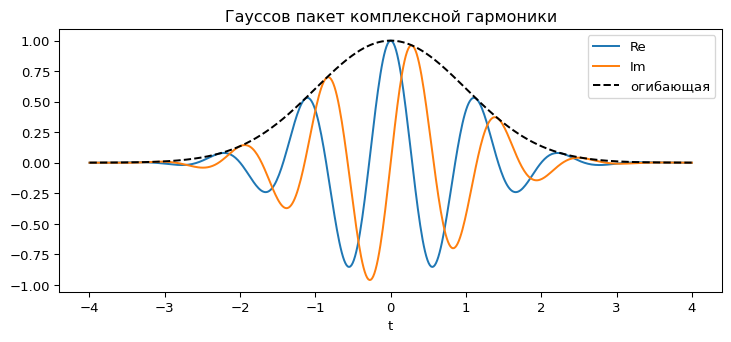

In [2]:
t=np.linspace(-4,4,500)
omega=5.5
wavelet=np.exp(-t*t/2)*np.exp(1j*omega*t)
plt.plot(t,wavelet.real,label='Re'); plt.plot(t,wavelet.imag,label='Im')
plt.plot(t,np.abs(wavelet),'k--',label='огибающая')
plt.xlabel('t'); plt.legend(); plt.title('Гауссов пакет комплексной гармоники'); plt.show()

## 2. Откуда берётся фаза коэффициента

В малой окрестности $\varphi(x)\approx\varphi(b)+\varphi'(b)(x-b)$, а a(x),b(x)
интерферограммы считаем медленно меняющимися. Положительная гармоника сигнала
взаимодействует с согласованной частотой ядра, отрицательная подавляется.
Тогда $W(a,b)\approx K(a,b)e^{i\varphi(b)}$ с положительным K в благоприятном режиме.
Аргумент W оценивает локальную фазу.

Ищем гребень: масштаб, где |W| велик. Приближённо $a\varphi'(b)\approx\omega_0$,
то есть период $T\approx2\pi a/\omega_0$. Точное положение максимума зависит от
нормировки и изменения амплитуды, поэтому это приближение, а не универсальный
точный частотомер. В учебной функции сравниваются несколько масштабов по каждой точке.

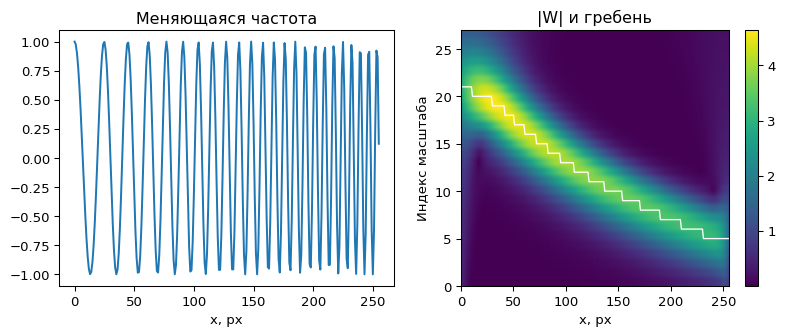

In [3]:
x=np.arange(256)
cycles=.035*x+.00022*x*x
chirp=np.cos(2*np.pi*cycles)
periods=np.geomspace(5,35,28)
coefficients=[]
for period in periods:
    scale=5.5*period/(2*np.pi)
    support=int(np.ceil(4*scale))
    u=np.arange(-support,support+1)/scale
    kernel=np.exp(-u*u/2)*np.exp(1j*5.5*u)
    kernel-=kernel.mean(); kernel/=np.sqrt(scale)
    coefficients.append(signal.fftconvolve(chirp,kernel,mode='same'))
coefficients=np.array(coefficients)
ridge=np.argmax(np.abs(coefficients),axis=0)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot(x,chirp); axes[0].set(title='Меняющаяся частота',xlabel='x, px')
im=axes[1].imshow(np.abs(coefficients),origin='lower',aspect='auto',extent=(0,255,0,len(periods)-1))
axes[1].plot(x,ridge,'w',lw=1); axes[1].set(title='|W| и гребень',xlabel='x, px',ylabel='Индекс масштаба')
fig.colorbar(im,ax=axes[1]); plt.show()

## 3. Двумерная картинка не делает фильтр двумерным

Если свёртка идёт вдоль X, нужна заметная вариация фазы по X. Для горизонтальных
полос яркость меняется по Y, и применение того же фильтра по строкам не извлекает
нужную фазу. Можно выбрать ось, повернуть изображение или использовать настоящий
ориентированный 2D вейвлет. Это разные алгоритмические решения.

Учебная функция поддерживает явный выбор оси. Для гребня требуются достаточно
широкий диапазон масштабов и амплитудная проверка; при нулевой модуляции фаза
комплексного коэффициента не несёт надёжной информации.

по X {'rms': 3.2623802862353903, 'pv': 12.417582435778545, 'bias': 1.0123753716055552, 'coverage': 0.8443820224719101}
по Y {'rms': 0.0003346018909689178, 'pv': 0.0013474417914844938, 'bias': 1.0033814759172974, 'coverage': 1.0}


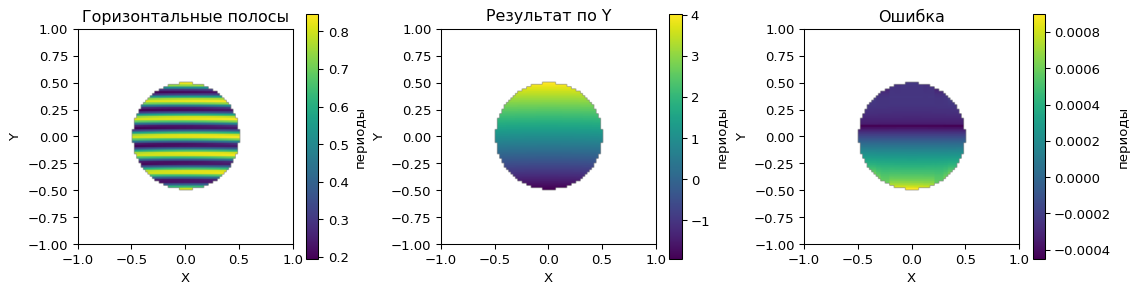

In [4]:
s=cl.scene(n=96,carrier_x=0,carrier_y=12,bowl=.15,astig=0)
periods=np.geomspace(4,16,18)
wrong,q_wrong=cl.cwt_phase(s['image'],s['mask'],periods,axis=1)
correct,q_correct=cl.cwt_phase(s['image'],s['mask'],periods,axis=0)
roi=s['mask']&(s['x']**2+s['y']**2<.5**2)
for name,phi in [('по X',wrong),('по Y',correct)]:
    print(name,cl.compare(phi/cl.TAU,s['orders'],roi)[1])
error,stats=cl.compare(correct/cl.TAU,s['orders'],roi)
cl.show_maps([s['image'],correct/cl.TAU,error],['Горизонтальные полосы','Результат по Y','Ошибка'],roi,units='периоды')

## 4. Край окна — область меньшей достоверности

Если ядро пересекает границу поля или отверстие, симметрия свёртки нарушается.
С одной стороны нет данных; амплитуда и аргумент могут измениться даже при идеальной
синусоиде. Большие масштабы сильнее страдают от края. Плавный фон также просачивается
через конечное окно. Отдельные шаги обработки: оценить фон; извлечь коэффициенты;
отобрать надёжные точки; развернуть фазу; оценить погрешность по области.

Преимущество локального окна не означает, что оно автоматически решает все эти задачи.

## Задания

1. Уменьшите диапазон periods так, чтобы истинного периода в нём не было.
2. Поверните полосы на диагональ; сравните анализ по X и по Y.
3. Сравните ошибку центральной области и кольца около края апертуры.
4. Объясните, почему надо хранить качество и маску рядом с фазой.

<details><summary>Разбор</summary>

Гребень прижимается к краю доступных масштабов, а результат становится смещённым.
Для диагонали важны проекции локальной частоты на оси. У края окно усечено;
одно поле чисел без маски скроет, где измерение перестало быть достоверным.
</details>

**Чтение:** [Zhong–Weng, 2004](https://opg.optica.org/ao/abstract.cfm?uri=ao-43-26-4993).
**В проекте:** `wavelet_phase_plugin` выполняет одномерный анализ по X; исследуйте,
какие предположения он делает о фоне и направлении полос.
Далее: [развёртка](07_phase_unwrapping.ipynb).